<a href="https://colab.research.google.com/github/Evgeniya-analyst/evgeniya-analyst.github.io/blob/master/%D0%94%D0%B5%D0%BD%D1%8C_2_Pandas_%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B0_%D0%B7_%D1%82%D0%B0%D0%B1%D0%BB%D0%B8%D1%87%D0%BD%D0%B8%D0%BC%D0%B8_%D0%B4%D0%B0%D0%BD%D0%B8%D0%BC%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Введення в аналіз даних і Pandas

Щоб проаналізувати набір даних, ви повинні виконати такі загальні дії:

- Імпорт бібліотек
- Завантаження даних
- Дослідження структури даних
- Чистка і трансформація типів даних
- Візуалізація даних
- Аналіз даних (статистичний аналіз, додаваня нових колонок, тощо)
- Опис результатів спостережень


## Огляд бібліотеки Pandas
Pandas — це бібліотека Python, яка використовується для обробки та аналізу даних. У прикладі коду ми імпортували Pandas за допомогою псевдоніма pd, який зазвичай використовується в коді Python.

In [94]:
import pandas as pd

**УВАГА!** В Colab бібліотека `pandas` вже є встановленою, а якщо ви працюєте з Jupyter notebook локально - її треба встановити наступним чином:

In [65]:
!pip install pandas

In [68]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [93]:
! ls

drive  sample_data


## Читання даних із файлів CSV

### Як завантажити готові набори даних

Pandas може читати дані з різних форматів файлів, включаючи файли CSV(comma-separated values).
Давайте зчитаємо дані з файлів, які є в Colaboratory. У прикладі коду ми використали функцію `read_csv()` для читання даних із файлу CSV під назвою `california_housing_train.csv`. Отримані дані зберігаються в змінній `df`, скорочено від `data frame`.






In [92]:
df = pd.read_csv('/content/drive/MyDrive/Analytics/avocado.csv')

In [91]:
type(df)

pandas.core.frame.DataFrame

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), int64(2), object(3)
memory usage: 1.9+ MB


Переглянути перші 5 записів:

In [6]:
df.head() # df.head(5)

,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [7]:
df['Unnamed: 0']

,Unnamed: 0
0,0
1,1
2,2
3,3
4,4
...,...
18244,7
18245,8
18246,9
18247,10


In [8]:
df['Unnamed: 0'].max()

52

In [9]:
df[df.region=='Albany'][df.year==2015][df.type=='conventional']

/tmp/ipykernel_1452/1267383190.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df.region=='Albany'][df.year==2015][df.type=='conventional']
/tmp/ipykernel_1452/1267383190.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df[df.region=='Albany'][df.year==2015][df.type=='conventional']


,Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.00,conventional,2015,Albany
1,1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.00,conventional,2015,Albany
2,2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.00,conventional,2015,Albany
3,3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.00,conventional,2015,Albany
4,4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.00,conventional,2015,Albany
5,5,2015-11-22,1.26,55979.78,1184.27,48067.99,43.61,6683.91,6556.47,127.44,0.00,conventional,2015,Albany
6,6,2015-11-15,0.99,83453.76,1368.92,73672.72,93.26,8318.86,8196.81,122.05,0.00,conventional,2015,Albany
7,7,2015-11-08,0.98,109428.33,703.75,101815.36,80.00,6829.22,6266.85,562.37,0.00,conventional,2015,Albany
8,8,2015-11-01,1.02,99811.42,1022.15,87315.57,85.34,11388.36,11104.53,283.83,0.00,conventional,2015,Albany
9,9,2015-10-25,1.07,74338.76,842.40,64757.44,113.00,8625.92,8061.47,564.45,0.00,conventional,2015,Albany


Також можна взяти набори даних з бібліотек, наприклад з бібліотеки для роботи з моделями машинного навчання `sklearn`. Детальніше про завантаження наборів даних з `sklearn` можна почитати в документації [тут](https://scikit-learn.org/stable/datasets.html). А поки розглянемо приклад:

In [10]:
df = df.drop(columns='Unnamed: 0')

In [11]:
df.head()

,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [12]:
df.rename(columns={'4046':'Small Number', '4225':'Large Number', '4770':'XLarge Number'}, inplace=True)

In [13]:
df.head()

,Date,AveragePrice,Total Volume,Small Number,Large Number,XLarge Number,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany


In [14]:
df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1)

,0
0,64236.62
1,54876.98
2,118220.22
3,78992.15
4,51039.60
...,...
18244,17074.83
18245,13888.04
18246,13766.76
18247,16205.22


In [15]:
df['Total Volume'].equals(df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1))

False

In [16]:
df['Check Sum'] = df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1)

In [72]:
import numpy as np

In [18]:
df['Check Passed'] = np.isclose(df['Check Sum'], df['Total Volume'])

In [19]:
df['Check Passed']

,Check Passed
0,True
1,True
2,True
3,True
4,True
...,...
18244,True
18245,True
18246,True
18247,True


In [20]:
df['Check Passed'].value_counts()

,count
Check Passed,
True,18073
False,176


In [21]:
# df['Check Passed Equals'] = df['Check Sum'] == df['Total Volume']

In [22]:
# df['Check Passed Equals'].value_counts()

In [23]:
df[df['Check Passed']==False][['Total Volume', 'Check Sum']]

,Total Volume,Check Sum
5622,97273.00,97274.00
5781,60602.00,60603.00
6841,79284.00,79285.00
7581,307299.00,307295.00
7687,166540.00,166533.00
...,...,...
18220,1384683.41,1384435.49
18221,1336979.09,1336826.61
18222,1283987.65,1283776.69
18223,1476651.08,1476524.24


In [24]:
filtered = df[df['Check Passed']==False]

In [25]:
filtered

,Date,AveragePrice,Total Volume,Small Number,Large Number,XLarge Number,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region,Check Sum,Check Passed
5622,2017-11-19,1.65,97273.00,2695.00,80596.00,43.00,13940.00,7536.00,6404.00,0.00,conventional,2017,Albany,97274.00,False
5781,2017-11-19,1.42,60602.00,31177.00,2085.00,5660.00,21681.00,14002.00,7421.00,258.00,conventional,2017,Boise,60603.00,False
6841,2017-11-19,1.18,79284.00,2182.00,33869.00,79.00,43155.00,12675.00,30480.00,0.00,conventional,2017,Louisville,79285.00,False
7581,2017-12-03,1.18,307299.00,91761.00,119171.00,3892.00,92471.00,89249.00,3222.00,0.00,conventional,2017,RaleighGreensboro,307295.00,False
7687,2017-12-03,0.99,166540.00,56316.00,47267.00,149.00,62801.00,57210.00,5518.00,73.00,conventional,2017,Roanoke,166533.00,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18220,2018-02-04,1.53,1384683.41,117922.52,287724.61,1703.52,977084.84,774695.74,201878.69,510.41,organic,2018,TotalUS,1384435.49,False
18221,2018-01-28,1.61,1336979.09,118616.17,280080.34,1270.61,936859.49,796104.27,140652.84,102.38,organic,2018,TotalUS,1336826.61,False
18222,2018-01-21,1.63,1283987.65,108705.28,259172.13,1490.02,914409.26,710654.40,203526.59,228.27,organic,2018,TotalUS,1283776.69,False
18223,2018-01-14,1.59,1476651.08,145680.62,323669.83,1580.01,1005593.78,858772.69,146808.97,12.12,organic,2018,TotalUS,1476524.24,False


In [26]:
(filtered['Total Volume'] - filtered['Check Sum'])/filtered['Check Sum']

,0
5622,-0.000010
5781,-0.000017
6841,-0.000013
7581,0.000013
7687,0.000042
...,...
18220,0.000179
18221,0.000114
18222,0.000164
18223,0.000086


In [27]:
difference_col = (filtered['Total Volume'] - filtered['Check Sum'])/filtered['Check Sum']

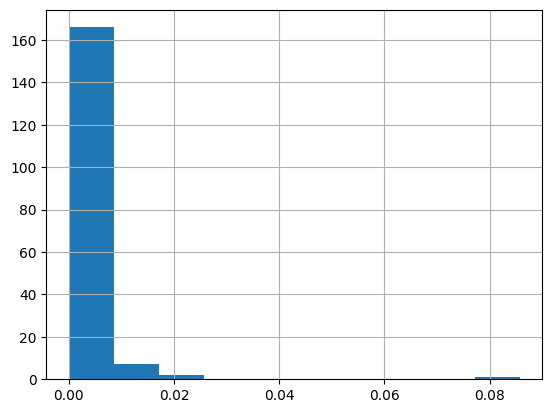

In [28]:
difference_col.hist();

In [29]:
df.rename(columns = {'Total Volume':'Total Volume Errors', 'Check Sum':'Total Volume'}, inplace=True)

In [30]:
df.head()

,Date,AveragePrice,Total Volume Errors,Small Number,Large Number,XLarge Number,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region,Total Volume,Check Passed
0,2015-12-27,1.33,64236.62,1036.74,54454.85,48.16,8696.87,8603.62,93.25,0.0,conventional,2015,Albany,64236.62,True
1,2015-12-20,1.35,54876.98,674.28,44638.81,58.33,9505.56,9408.07,97.49,0.0,conventional,2015,Albany,54876.98,True
2,2015-12-13,0.93,118220.22,794.70,109149.67,130.50,8145.35,8042.21,103.14,0.0,conventional,2015,Albany,118220.22,True
3,2015-12-06,1.08,78992.15,1132.00,71976.41,72.58,5811.16,5677.40,133.76,0.0,conventional,2015,Albany,78992.15,True
4,2015-11-29,1.28,51039.60,941.48,43838.39,75.78,6183.95,5986.26,197.69,0.0,conventional,2015,Albany,51039.60,True


In [38]:
df_grouped = df.groupby('type').agg(avg_volume=('Total Volume', 'mean'))

In [39]:
df_grouped

,avg_volume
type,
conventional,1.653213e+06
organic,4.780705e+04


In [40]:
df_grouped['percentage'] = (df_grouped['avg_volume'] / df_grouped['avg_volume'].sum())*100

In [41]:
df_grouped

,avg_volume,percentage
type,,
conventional,1.653213e+06,97.189507
organic,4.780705e+04,2.810493


In [82]:
type(df_grouped)

pandas.core.frame.DataFrame

In [42]:
df_grouped.round(2)

,avg_volume,percentage
type,,
conventional,1653212.90,97.19
organic,47807.05,2.81


In [53]:
df_grouped = df.groupby('type').agg(avg_price=('AveragePrice', 'mean'))

In [54]:
df_grouped

,avg_price
type,
conventional,1.158040
organic,1.653999


In [76]:
df_conv = [df['type']=='conventional']

In [86]:
df_conv_by_region = df_conv.groupby('region').AveragePrice.mean().sort_values()

KeyError: 'region'

In [81]:
df_conv_by_region

NameError: name 'df_conv_by_region' is not defined

In [ ]:
from sklearn.datasets import load_diabetes

In [ ]:
loaded = load_diabetes(as_frame=True)

In [ ]:
loaded

**Завдання 1**:
Виведіть перші 3 значення даних зі змінної `loaded`.

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
loaded.data.head(3)

```
</details>

Це були приклади, де взяти вже готові набори даних. Ми же сьогодні будемо працювати з іншим набором даних, бо він більш типовий для роботи аналітика.

### Набір даних `avocado`


В цьому уроці ми викоритовуємо дані про продажі авокадо. Детальний опис даних доступний [тут](https://www.kaggle.com/datasets/neuromusic/avocado-prices).
Основні колонки в даних:

- `Date` - The date of the observation
- `AveragePrice` - the average price of a single avocado
- `type` - conventional or organic
- `year` - the year
- `Region` - the city or region of the observation
- `Total Volume` - Total number of avocados sold

Перед виконанням подальших завдань треба завантажити свій набір даних на диск.

Але перед читанням нам треба замаунтити наш гугл диск.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Так можна визначити, який шлях до даних буде правильний.

In [32]:
! ls 'drive/MyDrive/Instagram/Майстер клас Python for DA'

ls: cannot access 'drive/MyDrive/Instagram/Майстер клас Python for DA': No such file or directory


In [ ]:
df = pd.read_csv('drive/MyDrive/Instagram/Майстер клас Python for DA/avocado.csv')

В першу чергу ми завжди дивимось на основні характеристики наших даних.

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), int64(2), object(3)
memory usage: 1.9+ MB


Ми можемо також окремо подивитись тільки на розмір чи наявні колонки.

In [34]:
df.shape

(18249, 14)

In [35]:
df.columns

Index(['Unnamed: 0', 'Date', 'AveragePrice', 'Total Volume', '4046', '4225',
       '4770', 'Total Bags', 'Small Bags', 'Large Bags', 'XLarge Bags', 'type',
       'year', 'region'],
      dtype='object')

Також корисно подивитись на самі дані.

In [ ]:
df.head()

Бачимо, що у нас перша колонка якась дивна. Вона не мала в назви в файлі, того зчиталась як `Unnamed: 0`. Подивимось, що в ній за дані? А також дізнаємось, як нам взяти дані одної колонки.

In [ ]:
df['Unnamed: 0']

In [ ]:
df['Unnamed: 0'].value_counts()

До колонок, імена яких складаються лише з латинських літер, числен і підкреслювань і починаються на латинську літеру можна звертатись просто через крапку.

In [36]:
df.year

,year
0,2015
1,2015
2,2015
3,2015
4,2015
...,...
18244,2018
18245,2018
18246,2018
18247,2018


Але для назв з пробілами таке не проканає

In [37]:
df.Unnamed: 0

**Завдання 2**:
Виведіть перші 10 значень колонки `AveragePrice`.

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
df['AveragePrice'].head(10)

```
</details>

Це схоже на номер тижнів. Перевіримо, а заодно подивимось, як фільтрувати дані.

In [ ]:
df.type.value_counts()

In [ ]:
df[df.region=='Albany'][df.year==2015][df.type=='conventional']

**Завдання 3**:
Виведіть тільки ті записи, які мають рік `2018` і тип авокадо `organic`. Скільки ми маємо рядочків таких даних?

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
df_2018_organic = df[df.year==2018][df.type=='organic']
display(df_2018_organic)
display(df_2018_organic.shape)

```
</details>

Щось типу зворотнього номеру тижня :) Гадаю, нам ця інформація не стане в нагоді, тож просто видалимо цей стовпець.

In [ ]:
df.drop(columns=['Unnamed: 0'])

Аби застовувати зміни, нам треба записати кудись результат команди.

In [ ]:
df = df.drop(columns=['Unnamed: 0'])

Взагалі переглянути які є різні опції у кожної функції чи які є властивості обʼєкта можна наступним чином:

In [ ]:
?pd.read_csv

In [ ]:
?df

Перейменуємо колонки на більш інформативні назви. Колонки з нумеричною назвою насправді означають наступне
```
4046 - Total number of avocados with PLU 4046 sold
4225 - Total number of avocados with PLU 4225 sold
4770 - Total number of avocados with PLU 4770 sold
```

PLU в свою чергу моженмо трактувати наступним чином:

```
4046: non-organic small/medium Hass Avocados (~3-5 oz)
4225: non-organic large Hass Avocados (~8-10 oz)
4770: non-organic extra large Hass Avocados (~10-15 oz)
```

Перейменування робиться через метод `rename`.

In [ ]:
df.rename(columns={'4046': 'Small Number', '4225': 'Large Number', '4770': 'XLarge Number'})

Крім запису змін в ту ж змінну можемо ще скористатись параметром `inplace`.

In [ ]:
df.rename(columns={'4046': 'Small Number', '4225': 'Large Number', '4770': 'XLarge Number'}, inplace=True)

In [ ]:
df.columns

**Завдання 4**:
1. Виведіть поточні назви колонок в змінній `df`
2. Перейменуйте колонки так, аби вони складались лише з маленьких літер і підкреслювань, тобто наприклад, `Small Number` в `small_number`, `Large Number` в `large_number`, `XLarge Number`  в `xlarge_number` і т.д. Результат запишіть в НОВУ ЗМІННУ `df2`.
Максимально круто - якщо зробите це через цикл і роботу з рядками.

Для чого треба ця вправа. Зручніше до колонок звертатись просто через крапочку, без квадратних дужок. Тому ми зробимо цю вправу і будемо знати, як переводити колонки в потрібний нам формат, якщо вони з самого початку написані латинськими літерами з пробілами.

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

Перше підзавдання виконується просто:
```
df.columns
```

Друге підзавдання через цикл буде виглядати так:

```python
col_names_mapping = {
  col:'_'.join(col.lower().split())
  for col in df.columns
}
df2 = df.rename(columns=col_names_mapping)

```

Без циклу те саме буде виглядати так:
```python
col_names_mapping = {'Date': 'date',
 'AveragePrice': 'averageprice',
 'Total Volume': 'total_volume',
 'Small Number': 'small_number',
 'Large Number': 'large_number',
 'XLarge Number': 'xlarge_number',
 'Total Bags': 'total_bags',
 'Small Bags': 'small_bags',
 'Large Bags': 'large_bags',
 'XLarge Bags': 'xlarge_bags'}

 df2 = df.rename(columns=col_names_mapping)
 ```

Правда в другому варіанті писати ручками треба значно більше коду?
Тепер розумієте навіщо вміти працювати з рядками, знати про цикли і колекції? :)

</details>

## Валідація даних
У нас є колонка `Total Volume`, яка має бути рівною сумі всіх проданих авокадо, в сумочках і поштучно. Перевіримо це.

In [ ]:
df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1)

In [ ]:
df['Total Volume'].equals(df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1))

Не всюди умова виконується. Подивимось, в скількох даних не виконується.
Для початку запишемо обчислення в окрему колонку.

In [ ]:
df['Check Sum'] = df[['Small Number', 'Large Number', 'XLarge Number', 'Total Bags']].sum(axis=1)

Тепер маємо порівняти наші значення в колонках `Total Volume` і `Check Sum`. Зробимо це спеціальним методом з бібліотеки `numpy`.

In [ ]:
import numpy as np

In [ ]:
df['Check Passed'] = np.isclose(df['Total Volume'], df['Check Sum'])

Чому нам потрібно використовувати цей метод.

In [ ]:
np.isclose(12.5, 12.500000001), 12.5 == 12.500000001

In [ ]:
df['Check Passed'].value_counts()

**Завдання 5**:
Вище ми використали спеціальним метод для порівняння значень типу `float`. Давайте подивимось що б було, аби ми про нього не знали. Створіть колонку `Check Passed Equal`, в яку запишіть результат порівняння через оператор `==` значень у колонках `Total Volume` і `Check Sum`. Після цього виведіть скільки рядків в такому випадку НЕ пройдуть перевірку (тобто ми могли б думати, що там значення `Total Volume` - неправильне).

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
df['Check Passed Equal'] = df['Total Volume'] == df['Check Sum']
df['Check Passed Equal'].value_counts()

```

А насправді багато з цих рядочків містять коректне значення з доволі великою точністю і вважати обчислення в них неправильними було б некоректно.
</details>

Подивмось на дані, де у нас не пройшла перевірка.

In [ ]:
df[df['Check Passed']==False]

Подивимось, чи розбіжність між ообчисленою колонкою і оригінальною - велика.

In [ ]:
filtered = df[df['Check Passed']==False]
(
    (filtered['Total Volume'] - filtered['Check Sum'])/filtered['Check Sum']
).hist();

Різниця невелика. Тож, просто замість попердньої колонки ми запишемо наші обчислені дані.

In [ ]:
df.rename(columns = {'Total Volume':'Total Volume Errors', 'Check Sum': 'Total Volume'}, inplace=True)

**Завдання 6**: Виведіть перші 5 рядочків оновлених даних аби перевірити, який вигляд вони мають.

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
df.head()

```
</details>

## Дослідження даних

### Агрегація і фільтрація даних

Авокадо якого типу продаються більше?

In [ ]:
df_grouped = df.groupby('type').agg(avg_vol=('Total Volume', 'mean')).reset_index()
df_grouped['percentage'] = (df_grouped['avg_vol'] / df_grouped['avg_vol'].sum()) * 100

In [ ]:
df_grouped

In [ ]:
df_grouped.round(2)

**Завдання 7**: Знайдіть яким є сумарний обʼєм продажів авокадо по рокам.

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

Функція для агрегування буде наступною:
```python
df.groupby('year').agg(sum_vol=('Total Volume', 'sum'))
```

Вона нам виведе якусь абракадабру, це називається scientific (науковий) формат.

Але ми можемо його прибрати і зробити більш зрозумілий вигляд даних. Показую, як (дуже корисний функціонал):
```python
df.groupby('year').agg(sum_vol=('Total Volume', 'sum')).style.format("{:.1f}")
```
</details>

Отже, авокадо звичайні мають більші обʼєми продажів. А яка різниця у ціні на ці типи авокадо?

In [ ]:
df.groupby('type').agg('AveragePrice').mean()

В якому регіоні найдешевше і найдорожче звичайне авокадо? Для цього маємо спочатку відфільтрувати дані, а потім загрегувати і відсортувати.

In [ ]:
df_conv = df[df['type']=='conventional']

In [ ]:
df_conv_by_region = df_conv.groupby('region').AveragePrice.mean().sort_values()

Знайдемо максимальне і мінімальне значення.

In [ ]:
df_conv_by_region.min(), df_conv_by_region.max()

Чудово! Тепер ми можемо знайти назви регіонів з мінімальним і максимальним значеннями.

In [ ]:
display(
    df_conv_by_region[df_conv_by_region==df_conv_by_region.min()],
    df_conv_by_region[df_conv_by_region==df_conv_by_region.max()]
)

### Візуалізація даних

Візуалізуємо і порівняємо динаміку цін на авокадо в цілому, а також за типами.

In [ ]:
# Перетворимо стовпець "Date" на об'єкт datetime і відсортуємо DataFrame за датою
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')
df = df.sort_values(by='Date')

Побудова візуалізацій. Для початку імпортуємо дві бібліотеки які нам потрібні.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Побудуємо для початку найпростіший можливий вигляд графіку.

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df.Date, df.AveragePrice);

Так сталось, бо у нас дані по країнам. Відповідно дані "скачуть", бо обʼєми продажів у нас в різних країнах і для різних типів авокадо різні. "Приблизимо трохи дані"

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df.Date[:1000], df.AveragePrice[:1000]);

Що ж робити? Ну, наприклад, агрегувати дані.

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(df.groupby('Date').AveragePrice.mean());

Ми могли б трансформувати дані, а можемо натомість використати більш "розумну" бібліотеку для побудови графіка.

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='AveragePrice', data=df, alpha=0.3)
plt.title('Price Trend');

Значно краще, правда? :)
Тепер виведемо динаміку по типам авокадо.

In [ ]:
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='AveragePrice', hue='type', data=df, alpha=0.3)
plt.title('Price Trend by Type');

**Резюме:**
- Органічні авокадо: виходячи зі змін цін протягом тривалого часу, ми бачимо, що вони **дорожчі**.
- Звичайні авокадо: виходячи зі змін цін протягом тривалого часу, ми бачимо, що вони **дешевші**.

**Завдання 8**: Побудуйте графік динаміки цін на авокадо (обох типів) аналогічни до того, що ми щойно побудували, по типам авокадо, тільки для конкретного регіона - `Chicago`. Проаналізуйте графік. Чи схожа тенденція в Чикаго на загальну? В чому бачите відмінності? Чи було таке, що органічні авокадо були дешевші за звичайні?

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
plt.figure(figsize=(12, 6))
sns.lineplot(x='Date', y='AveragePrice', hue='type', data=df[df['region']=='Chicago'])
plt.title('Price Trend by Type');

```
Найдорожчі авокадо виходять у нас в , а найдешевші - в
</details>

Розглянемо ще один вид графіку - гістограма.

In [ ]:
sns.set(style='whitegrid')
sns.histplot(x='AveragePrice', data=df);

Ми можемо змінити кількість на частоту. А також можемо змінити кількість бінів.

In [ ]:
sns.histplot(x='AveragePrice', stat='probability', data=df, bins=20);

Детальніше про параметри методу можна дізнатись вже відомим нам способом через знак питання, або в [документації](https://seaborn.pydata.org/generated/seaborn.histplot.html).

Побудуємо гістограми по типам авокадо.

In [ ]:
sns.histplot(x='AveragePrice', hue='type', data=df);

**Завдання 9**: Побудуйте гістограми розподілів цін на авокадо за типами для регіона з найвищою ціною. Ми знаходили цей регіон раніше. В назві графіка зазначте назву регіона і що зображено на графіку (ми вивели розподіл цін на авокадо).

<details>
<summary>Натисніть тут аби побачити розвʼязок</summary>

```python
region_name = 'HartfordSpringfield'
sns.histplot(x='AveragePrice', hue='type', data=df[df.region==region_name])
plt.title('Prices distribution for avocados in '+region_name);
```
Найдорожчі авокадо виходять у нас в , а найдешевші - в
</details>

## Запис у файл CSV

**УВАГА:** Треба вставити шлях на СВОЄМУ гугл диску.

In [95]:
df.to_csv("/content/drive/MyDrive/Analytics/avocado_UPD.csv", index=False)

На цьому наш вступна частина у світ програмування і аналізу даних добігла кінця. Буду рада вашим враженням в чаті курсу та відміткам в інстаграмі. Заряджайте своє оточення бажанням вчитись!)